
# Homework 3 — Multilingual transformer

## 1. Experimental setup

I fine-tune XLM-RoBERTa for multilingual text classification, using the same group-aware validation split as in the classical baseline experiments.

My objective is to improve macro-F1, particularly for the human and fusion classes, while investigating the limitations of standard sequence truncation.

I compare the transformer against the word-level TF-IDF baseline, which achieved a validation macro-F1 of 0.87852.


In [4]:
import torch
import random
import numpy as np
import pandas as pd

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert torch.cuda.is_available(), "GPU is not available!"

device = torch.device("cuda")

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
    "GB"
)

print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
GPU: Tesla T4
GPU memory: 14.56 GB
CUDA available: True



## 2. Environment and data preparation

I use the XLM-RoBERTa base encoder with mixed-precision training on an NVIDIA Tesla T4 GPU.

I retain the group-aware validation split from the EDA and baseline experiments. For the initial encoder experiment, I select a reproducible stratified sample of 40,000 training documents while keeping the complete validation set unchanged.

This allows me to compare the transformer against the classical baseline on identical validation examples.

In [5]:
import os
import random
import numpy as np
import pandas as pd
import torch
import transformers

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Transformers: 5.22.1
PyTorch: 2.14.1+cu130
CUDA: True


In [6]:
import zipfile
import subprocess

from google.colab import userdata, drive

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"

DATA_DIR = Path("/content/hw3_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

os.environ["KAGGLE_API_TOKEN"] = (
    userdata.get("kaggle_token").strip()
)

required_files = [
    "train.csv",
    "test.csv",
    "sample_submission.csv"
]

if not all((DATA_DIR / name).exists() for name in required_files):
    subprocess.run(
        [
            "kaggle", "competitions", "download",
            "-c", COMPETITION,
            "-p", str(DATA_DIR)
        ],
        check=True
    )

    for archive_path in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(DATA_DIR)

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv"
)

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/UCU_AI_HW3")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

fold_df = pd.read_csv(
    PROJECT_DIR / "cv_folds_v1.csv",
    dtype={"id": str}
)

train_df = train_df.merge(
    fold_df[["id", "group_id", "cv_fold"]],
    on="id",
    how="left",
    validate="one_to_one"
)

assert train_df["cv_fold"].notna().all()
assert train_df["cv_fold"].between(0, 4).all()
assert train_df.groupby("group_id")["cv_fold"].nunique().max() == 1

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Saved folds loaded successfully.")

Mounted at /content/drive
Train: (272352, 7)
Test: (25000, 4)
Saved folds loaded successfully.


In [7]:
VALIDATION_FOLD = 0
TRAIN_SAMPLE_SIZE = 40_000

full_train = train_df[
    train_df["cv_fold"] != VALIDATION_FOLD
].copy()

val_df = train_df[
    train_df["cv_fold"] == VALIDATION_FOLD
].copy()

strata = (
    full_train["label"].astype(str) + "_" +
    full_train["lang"].astype(str) + "_" +
    full_train["domain"].astype(str)
)

train_sample, _ = train_test_split(
    full_train,
    train_size=TRAIN_SAMPLE_SIZE,
    stratify=strata,
    random_state=SEED
)

train_sample = train_sample.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_sample["id"]).isdisjoint(set(val_df["id"]))
assert set(train_sample["group_id"]).isdisjoint(set(val_df["group_id"]))

print("Training sample:", len(train_sample))
print("Validation set:", len(val_df))

print("\nTraining class distribution:")
display(
    train_sample["label"]
    .value_counts(normalize=True)
    .reindex(["human", "ai", "fusion"])
    .round(4)
)

print("\nValidation class distribution:")
display(
    val_df["label"]
    .value_counts(normalize=True)
    .reindex(["human", "ai", "fusion"])
    .round(4)
)

print("\nTraining language distribution:")
display(train_sample["lang"].value_counts())

Training sample: 40000
Validation set: 55031

Training class distribution:


,proportion
label,
human,0.2448
ai,0.4474
fusion,0.3078



Validation class distribution:


,proportion
label,
human,0.2458
ai,0.4492
fusion,0.3050



Training language distribution:


,count
lang,
en-EN,32239
de-DE,7761



## 3. Tokenization and dataset preparation

I tokenize the training and validation texts using the pretrained XLM-RoBERTa tokenizer.

For the initial experiment, I truncate sequences to a maximum of 512 tokens, matching the standard context limit of XLM-RoBERTa base.

I avoid padding all documents to a fixed length during preprocessing. Instead, I use dynamic padding during training to reduce unnecessary computation and GPU memory usage.

I encode the three target classes as integer labels and preserve the complete fixed validation set for comparison with the classical baseline.

In [8]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from datasets import Dataset

MODEL_NAME = "FacebookAI/xlm-roberta-base"
MAX_LENGTH = 512

CLASS_ORDER = ["human", "ai", "fusion"]

label2id = {
    label: idx
    for idx, label in enumerate(CLASS_ORDER)
}

id2label = {
    idx: label
    for label, idx in label2id.items()
}

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

print("Tokenizer:", tokenizer.__class__.__name__)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model length:", tokenizer.model_max_length)
print("Label mapping:", label2id)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Tokenizer: XLMRobertaTokenizer
Vocabulary size: 250002
Maximum model length: 512
Label mapping: {'human': 0, 'ai': 1, 'fusion': 2}


In [9]:
def prepare_dataset(df):
    data = df[["text", "label"]].copy()
    data["labels"] = data["label"].map(label2id).astype(int)

    return Dataset.from_pandas(
        data[["text", "labels"]],
        preserve_index=False
    )

train_dataset = prepare_dataset(train_sample)
val_dataset = prepare_dataset(val_df)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

train_tokenized = train_dataset.map(
    tokenize_batch,
    batched=True,
    batch_size=256,
    remove_columns=["text"],
    desc="Tokenizing training data"
)

val_tokenized = val_dataset.map(
    tokenize_batch,
    batched=True,
    batch_size=256,
    remove_columns=["text"],
    desc="Tokenizing validation data"
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8
)

print("Training documents:", len(train_tokenized))
print("Validation documents:", len(val_tokenized))

print("\nSample tokenized example:")
print({
    "sequence_length": len(train_tokenized[0]["input_ids"]),
    "label": train_tokenized[0]["labels"]
})

Tokenizing training data:   0%|          | 0/40000 [00:00<?, ? examples/s]

Tokenizing validation data:   0%|          | 0/55031 [00:00<?, ? examples/s]

Training documents: 40000
Validation documents: 55031

Sample tokenized example:
{'sequence_length': 512, 'label': 1}


In [10]:
train_token_lengths = np.array([
    len(ids) for ids in train_tokenized["input_ids"]
])

val_token_lengths = np.array([
    len(ids) for ids in val_tokenized["input_ids"]
])

print("Training token lengths:")
display(
    pd.Series(train_token_lengths)
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .round(1)
)

print("\nValidation token lengths:")
display(
    pd.Series(val_token_lengths)
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .round(1)
)

print("\nShare of sequences truncated to 512 tokens:")
print(f"Train: {(train_token_lengths == 512).mean():.2%}")
print(f"Validation: {(val_token_lengths == 512).mean():.2%}")

Training token lengths:


,0
count,40000.0
mean,429.4
std,138.6
min,24.0
25%,380.0
50%,512.0
75%,512.0
90%,512.0
95%,512.0
max,512.0



Validation token lengths:


,0
count,55031.0
mean,430.3
std,137.6
min,26.0
25%,381.0
50%,512.0
75%,512.0
90%,512.0
95%,512.0
max,512.0



Share of sequences truncated to 512 tokens:
Train: 63.98%
Validation: 64.20%



### Tokenization findings

I successfully tokenized 40,000 training documents and 55,031 validation documents using the XLM-RoBERTa tokenizer.

The tokenized length distributions are nearly identical across the two subsets, with mean lengths of 429.4 and 430.3 tokens, respectively. Approximately 64% of sequences reach the configured maximum length of 512 tokens.

This confirms that the standard encoder configuration cannot process the complete content of many documents. I retain 512-token truncation as the initial reference and plan to evaluate alternative long-document strategies in subsequent experiments.



## 4. Model initialization and GPU memory verification

I initialize XLM-RoBERTa with a three-class classification head and verify that the model can perform a complete optimization step on the available GPU.

I use a batch size of four and mixed FP16 precision. I also enable gradient checkpointing to reduce activation memory usage.

This short smoke test checks memory compatibility before the full fine-tuning experiment. It is not included in the final training run or model evaluation.


In [11]:
import gc
import torch

from transformers import AutoModelForSequenceClassification

gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

model.gradient_checkpointing_enable()
model.to("cuda")

print("Model:", MODEL_NAME)
print("Number of parameters:", f"{model.num_parameters():,}")
print("Gradient checkpointing:", model.is_gradient_checkpointing)

print(
    "GPU memory allocated:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: FacebookAI/xlm-roberta-base
Number of parameters: 278,045,955
Gradient checkpointing: True
GPU memory allocated: 1.04 GB


In [12]:
from torch.optim import AdamW

SMOKE_BATCH_SIZE = 4

smoke_examples = [
    train_tokenized[i]
    for i in range(SMOKE_BATCH_SIZE)
]

smoke_batch = data_collator(smoke_examples)
smoke_batch = {
    key: value.to("cuda")
    for key, value in smoke_batch.items()
}

model.train()
optimizer = AdamW(model.parameters(), lr=2e-5)
scaler = torch.amp.GradScaler("cuda")

torch.cuda.reset_peak_memory_stats()

optimizer.zero_grad(set_to_none=True)

with torch.autocast(device_type="cuda", dtype=torch.float16):
    outputs = model(**smoke_batch)
    loss = outputs.loss

scaler.scale(loss).backward()
scaler.step(optimizer)
scaler.update()
optimizer.zero_grad(set_to_none=True)

print(f"Smoke-test loss: {loss.item():.4f}")
print(
    "Peak GPU memory:",
    f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
)

del optimizer, scaler, smoke_batch, smoke_examples, outputs, loss
del model
gc.collect()
torch.cuda.empty_cache()

print("Smoke test completed. Model released from memory.")

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Smoke-test loss: 1.1880
Peak GPU memory: 5.23 GB
Smoke test completed. Model released from memory.



## 5. Training configuration and performance benchmark

Before running the full fine-tuning experiment, I benchmark a short training run with 20 optimizer steps.

I use FP16 mixed precision, gradient accumulation, and gradient checkpointing to reduce GPU memory requirements. The benchmark uses a freshly initialized classification model and a subset of the training data.

I measure training throughput and peak GPU memory usage to verify that the configuration is suitable for longer training. The benchmark model will not be used for final evaluation or submission.


In [19]:
import time
import gc
import math

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

gc.collect()
torch.cuda.empty_cache()

benchmark_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(CLASS_ORDER),
    id2label=id2label,
    label2id=label2id
)

benchmark_args = TrainingArguments(
    output_dir="/content/xlmr_benchmark",
    max_steps=20,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=8,
    learning_rate=2e-5,
    weight_decay=0.01,
    fp16=True,
    gradient_checkpointing=True,
    logging_steps=5,
    eval_strategy="no",
    save_strategy="no",
    report_to="none",
    dataloader_num_workers=2,
    seed=SEED
)

benchmark_trainer = Trainer(
    model=benchmark_model,
    args=benchmark_args,
    train_dataset=train_tokenized.select(range(1024)),
    data_collator=data_collator,
    processing_class=tokenizer
)

print("Benchmark trainer configured.")
print("Effective batch size:", 4 * 8)
print("Optimizer steps:", benchmark_args.max_steps)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Benchmark trainer configured.
Effective batch size: 32
Optimizer steps: 20


In [20]:
torch.cuda.reset_peak_memory_stats()

start_time = time.perf_counter()

benchmark_result = benchmark_trainer.train()

elapsed = time.perf_counter() - start_time

print(f"\nBenchmark time: {elapsed:.1f} seconds")
print(f"Seconds per optimizer step: {elapsed / 20:.2f}")
print(
    "Peak GPU memory:",
    f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
)

estimated_steps = math.ceil(40000 / 32) * 3

print(f"Planned optimizer steps for 3 epochs: ~{estimated_steps:,}")
print(
    "Rough projected training hours:",
    round(elapsed / 20 * estimated_steps / 3600, 2)
)

Step,Training Loss
5,8.899902
10,8.361292
15,9.538782
20,9.113965



Benchmark time: 36.9 seconds
Seconds per optimizer step: 1.85
Peak GPU memory: 4.92 GB
Planned optimizer steps for 3 epochs: ~3,750
Rough projected training hours: 1.92



### Training loss verification

The short benchmark completed successfully with an average of 2.02 seconds per optimizer step and a peak GPU memory allocation of 4.92 GB.

However, the logged training losses were unexpectedly high for a three-class classification task. Before proceeding, I compare the model's directly computed cross-entropy loss with the values reported by the Trainer.

This verification helps distinguish a logging or gradient-accumulation scaling issue from an actual optimization problem.

In [21]:
import torch
import torch.nn.functional as F

benchmark_model.eval()

batch = data_collator([
    train_tokenized[i] for i in range(8)
])

batch = {
    key: value.to("cuda")
    for key, value in batch.items()
}

with torch.inference_mode():
    with torch.autocast("cuda", dtype=torch.float16):
        outputs = benchmark_model(**batch)

direct_ce = F.cross_entropy(
    outputs.logits.float(),
    batch["labels"]
)

print(f"Model-reported loss: {outputs.loss.item():.4f}")
print(f"Direct cross-entropy: {direct_ce.item():.4f}")
print(f"Loss is finite: {torch.isfinite(direct_ce).item()}")

predictions = outputs.logits.argmax(dim=-1)

print("True labels:", batch["labels"].cpu().tolist())
print("Predicted labels:", predictions.cpu().tolist())

del batch, outputs, predictions
torch.cuda.empty_cache()

Model-reported loss: 1.0121
Direct cross-entropy: 1.0121
Loss is finite: True
True labels: [1, 1, 2, 2, 0, 2, 1, 0]
Predicted labels: [1, 1, 1, 1, 1, 1, 1, 1]



## 6. Full model fine-tuning

I fine-tune XLM-RoBERTa on 40,000 stratified training examples using FP16 mixed precision and gradient accumulation.

I evaluate the model on the complete fixed validation set after each epoch. I monitor macro-F1 as the primary metric and track the F1 score of each class separately.

I use a linear learning-rate schedule with warmup, weight decay, and activation checkpointing. The best model is selected based on validation macro-F1, with early stopping to reduce unnecessary training.

In [22]:
from sklearn.metrics import f1_score, accuracy_score
from transformers import EvalPrediction

def compute_metrics(eval_pred: EvalPrediction):
    logits = eval_pred.predictions

    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)
    labels = eval_pred.label_ids

    per_class_f1 = f1_score(
        labels,
        predictions,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )

    return {
        "macro_f1": f1_score(
            labels,
            predictions,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0
        ),
        "accuracy": accuracy_score(labels, predictions),
        "human_f1": per_class_f1[0],
        "ai_f1": per_class_f1[1],
        "fusion_f1": per_class_f1[2]
    }

print("Evaluation metrics configured.")

Evaluation metrics configured.


In [24]:
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

import gc

for name in ["benchmark_trainer", "benchmark_model"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

OUTPUT_DIR = str(
    PROJECT_DIR / "xlmr_base_40k_512"
)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=8,

    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=375,
    lr_scheduler_type="linear",

    fp16=True,
    gradient_checkpointing=True,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,
    eval_accumulation_steps=16,

    logging_strategy="steps",
    logging_steps=50,

    dataloader_num_workers=2,
    report_to="none",

    seed=SEED,
    data_seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print("Trainer configured successfully.")
print("Output directory:", OUTPUT_DIR)
print("Training examples:", len(train_tokenized))
print("Validation examples:", len(val_tokenized))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainer configured successfully.
Output directory: /content/drive/MyDrive/UCU_AI_HW3/xlmr_base_40k_512
Training examples: 40000
Validation examples: 55031


In [25]:
import time

start_time = time.perf_counter()

train_result = trainer.train()

elapsed = time.perf_counter() - start_time

print(f"\nTraining completed in {elapsed / 3600:.2f} hours")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy,Human F1,Ai F1,Fusion F1
1,2.565312,0.328534,0.829272,0.856208,0.746853,0.984359,0.756604
2,1.921887,0.284028,0.858504,0.881649,0.791889,0.986948,0.796676
3,1.587033,0.334958,0.843968,0.872417,0.740546,0.989004,0.802353


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed in 1.81 hours
Best checkpoint: /content/drive/MyDrive/UCU_AI_HW3/xlmr_base_40k_512/checkpoint-2500
Best validation macro-F1: 0.8585042834587729



## 7. Model evaluation and Kaggle submission

I evaluate the best XLM-RoBERTa checkpoint on the fixed validation set and compare its class-level performance with the classical baseline.

I then generate predictions for the complete competition test set, preserving the official submission order.

This experiment allows me to compare the transformer against the TF-IDF baseline using both validation macro-F1 and the Kaggle public leaderboard.


Validation macro-F1:
0.8585042834587729

Classification report:
              precision    recall  f1-score   support

       human     0.7445    0.8457    0.7919     13529
          ai     0.9783    0.9958    0.9869     24718
      fusion     0.8594    0.7425    0.7967     16784

    accuracy                         0.8816     55031
   macro avg     0.8607    0.8613    0.8585     55031
weighted avg     0.8845    0.8816    0.8810     55031



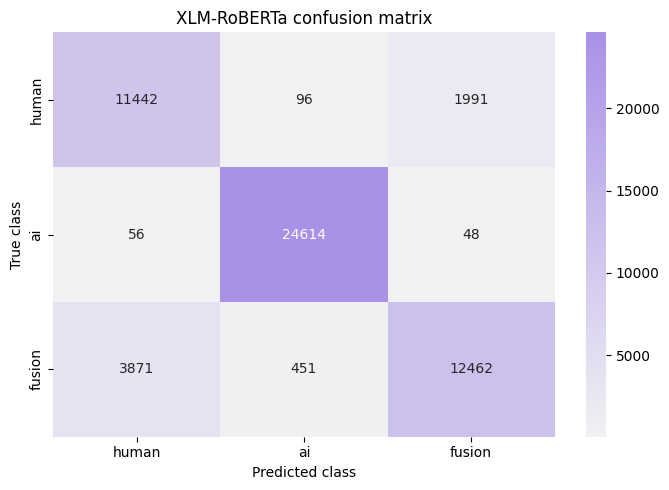

In [26]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

import seaborn as sns
import matplotlib.pyplot as plt

CLASS_ORDER = ["human", "ai", "fusion"]

val_output = trainer.predict(val_tokenized)

val_predictions = np.argmax(
    val_output.predictions,
    axis=-1
)

val_labels = val_output.label_ids

print("Validation macro-F1:")
print(f1_score(val_labels, val_predictions, average="macro"))

print("\nClassification report:")
print(
    classification_report(
        val_labels,
        val_predictions,
        target_names=CLASS_ORDER,
        digits=4
    )
)

cm = confusion_matrix(val_labels, val_predictions)

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=sns.light_palette("#A991E8", as_cmap=True),
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    ax=ax
)

ax.set(
    title="XLM-RoBERTa confusion matrix",
    xlabel="Predicted class",
    ylabel="True class"
)

plt.tight_layout()
plt.show()

In [27]:
from datasets import Dataset

test_dataset = Dataset.from_pandas(
    test_df[["text"]],
    preserve_index=False
)

test_tokenized = test_dataset.map(
    tokenize_batch,
    batched=True,
    batch_size=256,
    remove_columns=["text"],
    desc="Tokenizing test data"
)

test_output = trainer.predict(test_tokenized)

test_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

prediction_df = pd.DataFrame({
    "id": test_df["id"],
    "label": [id2label[int(p)] for p in test_predictions]
})

submission = sample_submission[["id"]].merge(
    prediction_df,
    on="id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == 25000
assert submission["id"].equals(sample_submission["id"])
assert submission["id"].is_unique
assert submission["label"].isin(CLASS_ORDER).all()

submission_path = PROJECT_DIR / "submission_xlmr_base_40k_512_v1.csv"

submission.to_csv(submission_path, index=False)

print("Saved:", submission_path)
print("\nPrediction distribution:")
display(submission["label"].value_counts())
display(submission.head())

Tokenizing test data:   0%|          | 0/25000 [00:00<?, ? examples/s]

Saved: /content/drive/MyDrive/UCU_AI_HW3/submission_xlmr_base_40k_512_v1.csv

Prediction distribution:


,count
label,
ai,13014
human,6732
fusion,5254


,id,label
0,8ff2d1,ai
1,a261cf,human
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


In [ ]:
BEST_CHECKPOINT = (
    PROJECT_DIR / "xlmr_base_40k_512" / "checkpoint-2500"
)

assert BEST_CHECKPOINT.is_dir(), (
    f"Missing checkpoint: {BEST_CHECKPOINT}"
)

assert trainer.state.best_model_checkpoint is not None
assert (
    Path(trainer.state.best_model_checkpoint).resolve()
    == BEST_CHECKPOINT.resolve()
), "The Trainer is not associated with checkpoint-2500."

inference_trainer = trainer
inference_trainer.model.eval()

print("Inference checkpoint:", BEST_CHECKPOINT)
print("Inference Trainer: PASSED")

In [28]:

import os
import gc
import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from tqdm.auto import tqdm

CHUNK_SIZE = 500

PREDICTIONS_DIR = PROJECT_DIR / "xlmr_cpu_predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ["human", "ai", "fusion"]

assert torch.cuda.is_available()
assert len(test_df) == 25_000

test_df = test_df.reset_index(drop=True)

def tokenize_test(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

num_chunks = (len(test_df) + CHUNK_SIZE - 1) // CHUNK_SIZE

completed = 0

for chunk_idx in tqdm(range(num_chunks), desc="GPU test inference"):

    start = chunk_idx * CHUNK_SIZE
    end = min(start + CHUNK_SIZE, len(test_df))

    chunk_path = (
        PREDICTIONS_DIR / f"predictions_{chunk_idx:03d}.csv"
    )

    expected_ids = (
        test_df.iloc[start:end]["id"]
        .astype(str)
        .reset_index(drop=True)
    )

    if chunk_path.exists():
        try:
            saved = pd.read_csv(
                chunk_path,
                dtype={"id": str}
            )

            valid = (
                list(saved.columns) == ["id", "label"]
                and len(saved) == len(expected_ids)
                and saved["id"].equals(expected_ids)
                and saved["label"].isin(CLASS_ORDER).all()
            )

            if valid:
                completed += 1
                continue

        except Exception:
            print(f"Invalid chunk found: {chunk_idx}")

    chunk_df = test_df.iloc[start:end]

    chunk_dataset = Dataset.from_pandas(
        chunk_df[["text"]],
        preserve_index=False
    )

    chunk_tokenized = chunk_dataset.map(
        tokenize_test,
        batched=True,
        batch_size=128,
        remove_columns=["text"],
        desc=f"Tokenizing chunk {chunk_idx + 1}",
        disable_nullable=True
    )

    prediction_output = inference_trainer.predict(
        chunk_tokenized
    )

    logits = prediction_output.predictions

    if isinstance(logits, tuple):
        logits = logits[0]

    predicted_ids = np.argmax(logits, axis=-1)

    chunk_predictions = pd.DataFrame({
        "id": expected_ids,
        "label": [
            id2label[int(pred)]
            for pred in predicted_ids
        ]
    })

    assert len(chunk_predictions) == end - start

    temporary_path = chunk_path.with_suffix(".tmp")

    chunk_predictions.to_csv(
        temporary_path,
        index=False
    )

    os.replace(temporary_path, chunk_path)

    completed += 1

    del chunk_dataset, chunk_tokenized, prediction_output, logits
    gc.collect()

print(f"\nCompleted chunks: {completed}/{num_chunks}")
print("GPU inference finished!")


GPU test inference:   0%|          | 0/50 [00:00<?, ?it/s]


Completed chunks: 50/50
GPU inference finished!


In [29]:

prediction_files = [
    PREDICTIONS_DIR / f"predictions_{i:03d}.csv"
    for i in range(num_chunks)
]

missing_files = [
    path.name
    for path in prediction_files
    if not path.exists()
]

assert not missing_files, (
    f"Missing prediction chunks: {missing_files}"
)

submission = pd.concat(
    [
        pd.read_csv(path, dtype={"id": str})
        for path in prediction_files
    ],
    ignore_index=True
)

assert len(submission) == 25_000
assert list(submission.columns) == ["id", "label"]

assert submission["id"].equals(
    test_df["id"].astype(str).reset_index(drop=True)
)

assert submission["id"].is_unique
assert submission["label"].isin(CLASS_ORDER).all()

submission_path = (
    PROJECT_DIR / "submission_xlmr_base_40k_512_v1.csv"
)

submission.to_csv(submission_path, index=False)

print("Submission created successfully!")
print("Path:", submission_path)
print("Rows:", len(submission))

print("\nPredicted class distribution:")
display(submission["label"].value_counts())

display(submission.head())


Submission created successfully!
Path: /content/drive/MyDrive/UCU_AI_HW3/submission_xlmr_base_40k_512_v1.csv
Rows: 25000

Predicted class distribution:


,count
label,
ai,12988
fusion,6855
human,5157


,id,label
0,8ff2d1,ai
1,a261cf,fusion
2,ad5614,fusion
3,3a23ac,ai
4,28b4e5,ai


In [30]:

from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = (
    userdata.get("kaggle_token").strip()
)

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"

!kaggle competitions submit \
    -c {COMPETITION} \
    -f {submission_path} \
    -m "XLM-RoBERTa base, 40k training samples, 512 tokens, 3 epochs"


100% 286k/286k [00:00<00:00, 492kB/s]
Successfully submitted to AI-Generated Text Detection | HW3 | UCU AI 2026


## 8. Long-text handling: head-tail truncation

The initial XLM-RoBERTa experiment uses standard head-only truncation to 512 tokens. However, a substantial proportion of documents exceed this limit, so the model cannot access information near their endings.

I investigate an alternative head-tail strategy that preserves the first 255 and last 255 content tokens, together with the model's special tokens.

I keep the fine-tuned checkpoint, validation split, and evaluation metric unchanged. Only the input construction changes, allowing me to measure the effect of long-text preprocessing independently of additional training.

I compare both strategies using validation macro-F1 and per-class F1, with particular attention to the `human` and `fusion` classes.


In [33]:
import numpy as np
import torch

MAX_LENGTH = 512

NUM_SPECIAL_TOKENS = 2
CONTENT_BUDGET = MAX_LENGTH - NUM_SPECIAL_TOKENS

HEAD_TOKENS = CONTENT_BUDGET // 2
TAIL_TOKENS = CONTENT_BUDGET - HEAD_TOKENS

assert tokenizer.cls_token_id is not None
assert tokenizer.sep_token_id is not None
assert tokenizer.num_special_tokens_to_add(pair=False) == 2

print("Maximum sequence length:", MAX_LENGTH)
print("Special tokens:", NUM_SPECIAL_TOKENS)
print("Head tokens:", HEAD_TOKENS)
print("Tail tokens:", TAIL_TOKENS)

def tokenize_head_tail(batch):
    encoded = tokenizer(
        batch["text"],
        add_special_tokens=False,
        truncation=False,
        padding=False,
        verbose=False
    )

    input_ids_batch = []
    attention_masks = []

    for token_ids in encoded["input_ids"]:

        if len(token_ids) > CONTENT_BUDGET:
            selected = (
                token_ids[:HEAD_TOKENS]
                + token_ids[-TAIL_TOKENS:]
            )
        else:
            selected = token_ids

        final_ids = (
            [tokenizer.cls_token_id]
            + selected
            + [tokenizer.sep_token_id]
        )

        assert len(final_ids) <= MAX_LENGTH

        input_ids_batch.append(final_ids)
        attention_masks.append([1] * len(final_ids))

    return {
        "input_ids": input_ids_batch,
        "attention_mask": attention_masks
    }

print("Head-tail tokenizer configured successfully.")

Maximum sequence length: 512
Special tokens: 2
Head tokens: 255
Tail tokens: 255
Head-tail tokenizer configured successfully.


In [34]:
sample_texts = val_df["text"].iloc[:5].tolist()

standard_encoded = tokenizer(
    sample_texts,
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

head_tail_encoded = tokenize_head_tail({
    "text": sample_texts
})

rows = []

for i, text in enumerate(sample_texts):
    full_ids = tokenizer(
        text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    head_tail_ids = head_tail_encoded["input_ids"][i]
    standard_ids = standard_encoded["input_ids"][i]

    rows.append({
        "sample": i,
        "original_tokens": len(full_ids),
        "standard_tokens": len(standard_ids),
        "head_tail_tokens": len(head_tail_ids),
        "head_tail_applied": len(full_ids) > CONTENT_BUDGET
    })

import pandas as pd

tokenization_check = pd.DataFrame(rows)

display(tokenization_check)

assert tokenization_check["standard_tokens"].le(512).all()
assert tokenization_check["head_tail_tokens"].le(512).all()

print("Head-tail tokenization verification: PASSED")

,sample,original_tokens,standard_tokens,head_tail_tokens,head_tail_applied
0,0,1195,512,512,True
1,1,50,52,52,False
2,2,576,512,512,True
3,3,779,512,512,True
4,4,832,512,512,True


Head-tail tokenization verification: PASSED



### Head-tail validation experiment

I evaluate head-tail truncation on the same fixed validation split used for the original XLM-RoBERTa experiment.

I keep the model weights unchanged and compare macro-F1, per-class F1, and the confusion matrix against standard head-only truncation.

This experiment tests whether preserving information from both ends of long documents improves classification, particularly for the `fusion` class.


In [35]:
from datasets import Dataset

assert len(val_df) == 55_031
assert len(val_tokenized) == len(val_df)
assert trainer.state.best_model_checkpoint is not None

print("Evaluating checkpoint:",
      trainer.state.best_model_checkpoint)

val_head_tail = Dataset.from_pandas(
    pd.DataFrame({
        "text": val_df["text"].to_numpy(),
        "labels": val_df["label"].map(label2id).to_numpy()
    }),
    preserve_index=False
)

val_head_tail = val_head_tail.map(
    tokenize_head_tail,
    batched=True,
    batch_size=64,
    remove_columns=["text"],
    desc="Tokenizing head-tail validation"
)

assert len(val_head_tail) == 55_031
assert all(
    len(ids) <= 512
    for ids in val_head_tail["input_ids"]
)

print("Head-tail validation dataset ready.")
print("Documents:", len(val_head_tail))

Evaluating checkpoint: /content/drive/MyDrive/UCU_AI_HW3/xlmr_base_40k_512/checkpoint-2500


Tokenizing head-tail validation:   0%|          | 0/55031 [00:00<?, ? examples/s]

Head-tail validation dataset ready.
Documents: 55031


In [36]:
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

head_tail_output = trainer.predict(val_head_tail)

head_tail_preds = np.argmax(
    head_tail_output.predictions,
    axis=-1
)

head_tail_labels = head_tail_output.label_ids

head_tail_macro_f1 = f1_score(
    head_tail_labels,
    head_tail_preds,
    average="macro"
)

print("Head-only macro-F1:",
      round(float(trainer.state.best_metric), 5))
print("Head-tail macro-F1:",
      round(head_tail_macro_f1, 5))

print("\nHead-tail classification report:")
print(
    classification_report(
        head_tail_labels,
        head_tail_preds,
        target_names=CLASS_ORDER,
        digits=4
    )
)

Head-only macro-F1: 0.8585
Head-tail macro-F1: 0.87345

Head-tail classification report:
              precision    recall  f1-score   support

       human     0.7842    0.8511    0.8163     13529
          ai     0.9837    0.9800    0.9819     24718
      fusion     0.8500    0.7962    0.8222     16784

    accuracy                         0.8923     55031
   macro avg     0.8726    0.8758    0.8734     55031
weighted avg     0.8939    0.8923    0.8925     55031




## 8.4. Final comparison of long-text strategies

I compare standard head-only and head-tail inference using the same fine-tuned checkpoint and the same validation documents.

I examine the effect of each strategy on shorter documents and documents reaching the 512-token limit. I also compare confusion matrices and class-specific F1 scores.

This analysis helps determine whether the performance improvement comes from retaining additional information in long documents and whether it reduces confusion between `human` and `fusion`.


In [37]:
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

head_only_preds = np.asarray(val_predictions)
head_tail_preds = np.asarray(head_tail_preds)
true_labels = np.asarray(head_tail_labels)

assert len(true_labels) == len(val_df) == 55_031
assert len(head_only_preds) == len(head_tail_preds)
assert np.array_equal(true_labels, np.asarray(val_labels))

token_lengths = np.array([
    len(ids) for ids in val_tokenized["input_ids"]
])

groups = {
    "Below 512 tokens": token_lengths < 512,
    "512-token sequences": token_lengths == 512,
    "All validation": np.ones(len(true_labels), dtype=bool)
}

comparison_rows = []

for group_name, mask in groups.items():
    head_f1 = f1_score(
        true_labels[mask],
        head_only_preds[mask],
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    tail_f1 = f1_score(
        true_labels[mask],
        head_tail_preds[mask],
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    comparison_rows.append({
        "group": group_name,
        "documents": int(mask.sum()),
        "head_only_f1": head_f1,
        "head_tail_f1": tail_f1,
        "improvement": tail_f1 - head_f1
    })

length_comparison = pd.DataFrame(comparison_rows)

display(length_comparison.round(5))

,group,documents,head_only_f1,head_tail_f1,improvement
0,Below 512 tokens,19701,0.88571,0.88571,0.00000
1,512-token sequences,35330,0.84061,0.86547,0.02486
2,All validation,55031,0.85850,0.87345,0.01494


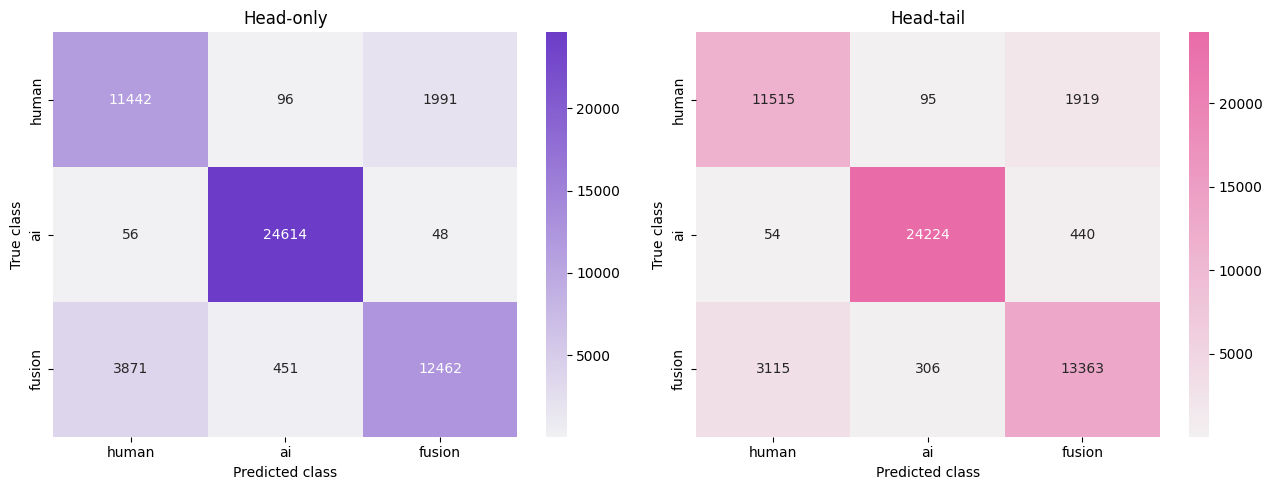

Human predicted as fusion:
Head-only: 1991
Head-tail: 1919

Fusion predicted as human:
Head-only: 3871
Head-tail: 3115


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

class_names = ["human", "ai", "fusion"]

head_cm = confusion_matrix(
    true_labels,
    head_only_preds,
    labels=[0, 1, 2]
)

tail_cm = confusion_matrix(
    true_labels,
    head_tail_preds,
    labels=[0, 1, 2]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, matrix, title, color in [
    (axes[0], head_cm, "Head-only", "#6C3CC8"),
    (axes[1], tail_cm, "Head-tail", "#E96BA8")
]:
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap=sns.light_palette(color, as_cmap=True),
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

plt.tight_layout()
plt.show()

print("Human predicted as fusion:")
print("Head-only:", head_cm[0, 2])
print("Head-tail:", tail_cm[0, 2])

print("\nFusion predicted as human:")
print("Head-only:", head_cm[2, 0])
print("Head-tail:", tail_cm[2, 0])


## 9. Save validation predictions for further experiments

I save the validation probabilities from the head-only and head-tail XLM-RoBERTa experiments for later model comparison and ensembling.

Both sets of probabilities correspond to the same checkpoint, validation fold, and document ordering. I preserve the true labels and document identifiers to prevent accidental misalignment.


In [39]:
from scipy.special import softmax
import numpy as np
import pandas as pd

head_only_probs = softmax(
    np.asarray(val_output.predictions),
    axis=1
)

head_tail_probs = softmax(
    np.asarray(head_tail_output.predictions),
    axis=1
)

assert head_only_probs.shape == (55031, 3)
assert head_tail_probs.shape == (55031, 3)
assert np.array_equal(val_output.label_ids, head_tail_output.label_ids)

probabilities_df = pd.DataFrame({
    "id": val_df["id"].astype(str).to_numpy(),
    "true_label": val_df["label"].to_numpy(),

    "head_human": head_only_probs[:, 0],
    "head_ai": head_only_probs[:, 1],
    "head_fusion": head_only_probs[:, 2],

    "headtail_human": head_tail_probs[:, 0],
    "headtail_ai": head_tail_probs[:, 1],
    "headtail_fusion": head_tail_probs[:, 2],
})

assert probabilities_df["id"].is_unique

probabilities_path = (
    PROJECT_DIR / "xlmr_checkpoint2500_validation_probs.csv"
)

probabilities_df.to_csv(probabilities_path, index=False)

print("Saved:", probabilities_path)
print("Rows:", len(probabilities_df))
print("Checkpoint: 2500")
print("Head-only macro-F1: 0.85850")
print("Head-tail macro-F1: 0.87345")

Saved: /content/drive/MyDrive/UCU_AI_HW3/xlmr_checkpoint2500_validation_probs.csv
Rows: 55031
Checkpoint: 2500
Head-only macro-F1: 0.85850
Head-tail macro-F1: 0.87345



## 10. Final encoder findings

I fine-tuned XLM-RoBERTa base on 40,000 stratified training documents and evaluated it on the fixed group-aware validation fold of 55,031 documents.

The best model was selected using validation macro-F1 and corresponds to checkpoint-2500. Standard head-only inference achieved 0.85850 macro-F1.

Because many documents exceed the 512-token limit, I evaluated a head-tail strategy that retains the beginning and ending of each document. Without additional fine-tuning, this improved macro-F1 to 0.87345.

The improvement was concentrated in documents reaching the token limit, while shorter documents produced unchanged predictions.

Although the transformer alone did not outperform the word-level TF-IDF baseline, its different representation of text made it a useful candidate for the subsequent ensemble experiments.

I saved aligned validation probabilities from checkpoint-2500 for reproducible model comparison and ensemble construction.
